In [1]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ravelry_scraper.constants import DATA_DIR

In [2]:
con = duckdb.connect()

parquet_files = list(DATA_DIR.glob("**/*.parquet"))

# Register Parquet datasets as SQL views
for file in parquet_files:
    name = f"{file.parent.name}_{file.stem}"
    con.execute(f"""
        CREATE OR REPLACE VIEW {name} AS
        SELECT *
        FROM read_parquet('{file}')
    """)


In [3]:
# Store list of all DuckDB views
duckdb_views = [row[0] for row in con.execute("""
    SELECT view_name
    FROM duckdb_views
""").fetchall()]

# Print all DuckDB views to verify the list
print(duckdb_views)

['extracted_crafts', 'extracted_languages', 'extracted_needle_sizes', 'extracted_pattern_attributes', 'extracted_pattern_categories', 'extracted_pattern_types', 'extracted_users', 'extracted_yarn_companies', 'extracted_yarn_fibers', 'extracted_yarn_weights', 'processed_designers', 'processed_patterns', 'processed_projects', 'processed_yarns', 'raw_designers', 'raw_patterns', 'raw_projects', 'raw_yarns']


# Patterns

TODO - describe findings

### Challenges and Limitations

TODO - scraping
TODO - storage
TODO - deduplication

In [4]:
con.sql("SELECT COUNT(*) AS total_patterns FROM raw_patterns").df()

,total_patterns
0,1261768


TODO - describe findings

In [5]:
con.execute(f"""
    DESCRIBE raw_patterns
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,comments_count,BIGINT,YES,None,None,None
1,created_at,VARCHAR,YES,None,None,None
2,currency,VARCHAR,YES,None,None,None
3,difficulty_average,DOUBLE,YES,None,None,None
4,difficulty_count,DOUBLE,YES,None,None,None
5,downloadable,BOOLEAN,YES,None,None,None
6,favorites_count,BIGINT,YES,None,None,None
7,free,BOOLEAN,YES,None,None,None
8,gauge,DOUBLE,YES,None,None,None
9,gauge_divisor,DOUBLE,YES,None,None,None


TODO - describe findings

In [6]:
con.execute(f"""
    SELECT
        COUNT(*) AS total_patterns,
        COUNT(DISTINCT id) AS unique_patterns,
        COUNT(price) AS has_price,
        COUNT(rating_average) AS has_rating,
        COUNT(difficulty_average) AS has_difficulty,
        COUNT(projects_count) AS has_projects,
        COUNT(favorites_count) AS has_favorites,
        COUNT(yardage) AS has_yardage
    FROM raw_patterns
""").fetchdf()

,total_patterns,unique_patterns,has_price,has_rating,has_difficulty,has_projects,has_favorites,has_yardage
0,1261768,1261768,614427,1261768,1261768,1261768,1261768,804551


TODO - describe findings

In [7]:
con.execute(f"""
    SELECT
        free,
        COUNT(*) AS total_patterns,
        COUNT(price) AS has_price,
        AVG(price) AS avg_price,
        AVG(rating_average) AS avg_rating,
        AVG(projects_count) AS avg_projects
    FROM raw_patterns
    GROUP BY free
    ORDER BY free
""").fetchdf()

,free,total_patterns,has_price,avg_price,avg_rating,avg_projects
0,False,939919,582216,15.032290,1.021012,15.126277
1,True,321833,32210,4.348432,1.475944,33.377892
2,<NA>,16,1,10.000000,2.263884,21.562500


In [8]:
con.execute(f"""
    DESCRIBE processed_patterns
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,comments_count,BIGINT,YES,None,None,None
1,created_at,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,currency,VARCHAR,YES,None,None,None
3,difficulty_average,DOUBLE,YES,None,None,None
4,difficulty_count,BIGINT,YES,None,None,None
5,downloadable,BIGINT,YES,None,None,None
6,favorites_count,BIGINT,YES,None,None,None
7,free,BIGINT,YES,None,None,None
8,id,BIGINT,YES,None,None,None
9,name,VARCHAR,YES,None,None,None


# Projects

Ravelry's API exposes an endpoint for `GET /projects/search.json` that returns user-created Project records. Each Project can be linked to one Pattern through `pattern_id`. This will let us combine pattern characteristics with project-level outcomes like completion status, time to finish, and overall engagement.

| **Notable Fields** | **Use Cases** |
| --- | --- |
| `id`, `pattern_id`, `pattern_name` | Identify Projects and join them to Patterns |
| `project_status_id`, `status_name`, `progress` | Measure project outcomes, like % marked completed |
| `started`, `completed` | Estimate time to completion |
| `comments_count`, `favorites_count`, `photos_count` | Analyze user engagement |

### Challenges and Limitations

Unlike other endpoints, Projects cannot be accessed sequentially via ID. To combat this, the `search_pipeline` was run with various queries and parameters. For example,
TODO - SEARCH_SORT_OPTIONS, queries?

However, we cannot know the exact level of sampling. According to Ravelry's documentation, there are at least 33 million Projects.
TODO

### Documentation
- https://www.ravelry.com/api#projects_search
- https://www.ravelry.com/api#Project__result

In [22]:
con.execute(f"""
    DESCRIBE raw_projects
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,comments_count,BIGINT,YES,None,None,None
1,completed,VARCHAR,YES,None,None,None
2,craft_id,DOUBLE,YES,None,None,None
3,created_at,VARCHAR,YES,None,None,None
4,favorites_count,BIGINT,YES,None,None,None
5,finish_by,VARCHAR,YES,None,None,None
6,id,BIGINT,YES,None,None,None
7,made_for,VARCHAR,YES,None,None,None
8,made_for_user_id,DOUBLE,YES,None,None,None
9,name,VARCHAR,YES,None,None,None


In [23]:
con.execute(f"""
    SELECT
        COUNT(*) AS total_projects,
        COUNT(pattern_id) AS with_pattern,
        COUNT(DISTINCT pattern_id) AS unique_patterns,
        COUNT(completed) AS completed,
        AVG(
            CAST(completed AS DATE) - CAST(started AS DATE)
        ) AS avg_completion_days
    FROM raw_projects
""").fetchdf()

,total_projects,with_pattern,unique_patterns,completed,avg_completion_days
0,99994,96468,17881,96004,35.198018


In [25]:
con.execute(f"""
    DESCRIBE processed_projects
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,comments_count,BIGINT,YES,None,None,None
1,completed,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,craft_id,BIGINT,YES,None,None,None
3,created_at,TIMESTAMP WITH TIME ZONE,YES,None,None,None
4,favorites_count,BIGINT,YES,None,None,None
5,id,BIGINT,YES,None,None,None
6,pattern_id,BIGINT,YES,None,None,None
7,project_status_changed,TIMESTAMP WITH TIME ZONE,YES,None,None,None
8,rating,DOUBLE,YES,None,None,None
9,started,TIMESTAMP WITH TIME ZONE,YES,None,None,None


In [12]:
con.execute(f"""
    SELECT
        COUNT(*) AS total_projects,
        COUNT(pattern_id) AS with_pattern,
        COUNT(DISTINCT pattern_id) AS unique_patterns,
        COUNT(completed) AS completed,
        AVG(
            CAST(completed AS DATE) - CAST(started AS DATE)
        ) AS avg_completion_days
    FROM processed_projects
""").fetchdf()

,total_projects,with_pattern,unique_patterns,completed,avg_completion_days
0,96018,96018,17675,92388,34.267541


In [13]:
# Most Popular Project Patterns
con.execute(f"""
    SELECT
        p.pattern_id,
        r.name AS pattern_name,
        COUNT(p.*) AS num_projects
    FROM processed_projects AS p
    JOIN raw_patterns AS r
        ON p.pattern_id = r.id
    GROUP BY p.pattern_id, r.name
    HAVING COUNT(p.*) > 250
    ORDER BY num_projects DESC
""").fetchdf()

,pattern_id,pattern_name,num_projects
0,754478,Ranunculus,1167
1,1255578,Step by Step Sweater,840
2,1285522,Lakes Pullover,602
3,857493,Oslo Hat,596
4,1258283,Sophie Scarf,593
5,1261294,Monday Sweater,405
6,1342098,Blouse No. 1,402
7,1219314,Winters Pullover,278
8,840489,Cumulus Blouse,272


In [14]:
# TODO - why is 2025 & 2024 missing?

# Most Popular Project Pattern by Year
con.execute(f"""
    WITH yearly_counts AS (
        SELECT
            pattern_id,
            COUNT(*) AS num_projects,
            EXTRACT(YEAR FROM created_at) AS year
        FROM processed_projects
        GROUP BY year, pattern_id
        ORDER BY year DESC
    ),
    ranked_counts AS (
        SELECT
            pattern_id,
            num_projects,
            year,
            RANK() OVER (PARTITION BY year ORDER BY num_projects DESC) AS rank
        FROM yearly_counts
    )
    SELECT 
        ranks.year,
        patterns.id,
        patterns.name,
        ranks.num_projects
    FROM ranked_counts AS ranks
    JOIN raw_patterns AS patterns
        ON ranks.pattern_id = patterns.id
    WHERE rank = 1
    ORDER BY year DESC
""").fetchdf()

,year,id,name,num_projects
0,2026,754478,Ranunculus,655
1,2023,1341627,Field Sweater,97
2,2022,754478,Ranunculus,56
3,2021,754478,Ranunculus,43
4,2020,754478,Ranunculus,25
5,2019,754478,Ranunculus,32
6,2018,754478,Ranunculus,24
7,2017,754478,Ranunculus,41
8,2016,630509,Mandala Madness,10
9,2016,414411,Seasonal dresses,10


In [ ]:
# Average Completion Time Variation by Year
con.execute("""
    WITH yearly_stats AS (
        SELECT
            EXTRACT(YEAR FROM created_at) AS year,
            ROUND(
                AVG(
                    CAST(completed AS DATE) - CAST(started AS DATE)
                )
                , 2
            ) AS avg_completion_time
        FROM processed_projects
        WHERE (
            completed IS NOT NULL AND 
            started IS NOT NULL AND
            completed >= started
        )
        GROUP BY year
        ORDER BY year
    )
    SELECT
        year,
        avg_completion_time,
        ROUND(
            avg_completion_time - LAG(avg_completion_time) OVER (ORDER BY year ASC), 
            2
        ) AS change_in_days,
        ROUND(
            ((avg_completion_time - LAG(avg_completion_time) OVER (ORDER BY year ASC)) 
            / NULLIF(LAG(avg_completion_time) OVER (ORDER BY year ASC), 0)) * 100, 
            2
        ) AS change_in_percentage
    FROM yearly_stats
    ORDER BY year
""").fetchdf()

,year,avg_completion_time,change_in_days,change_in_percentage
0,2007,89.14,NaN,NaN
1,2008,141.30,52.16,58.51
2,2009,72.76,-68.54,-48.51
3,2010,49.64,-23.12,-31.78
4,2011,72.73,23.09,46.51
5,2012,48.30,-24.43,-33.59
6,2013,59.23,10.93,22.63
7,2014,62.41,3.18,5.37
8,2015,66.34,3.93,6.30
9,2016,65.40,-0.94,-1.42


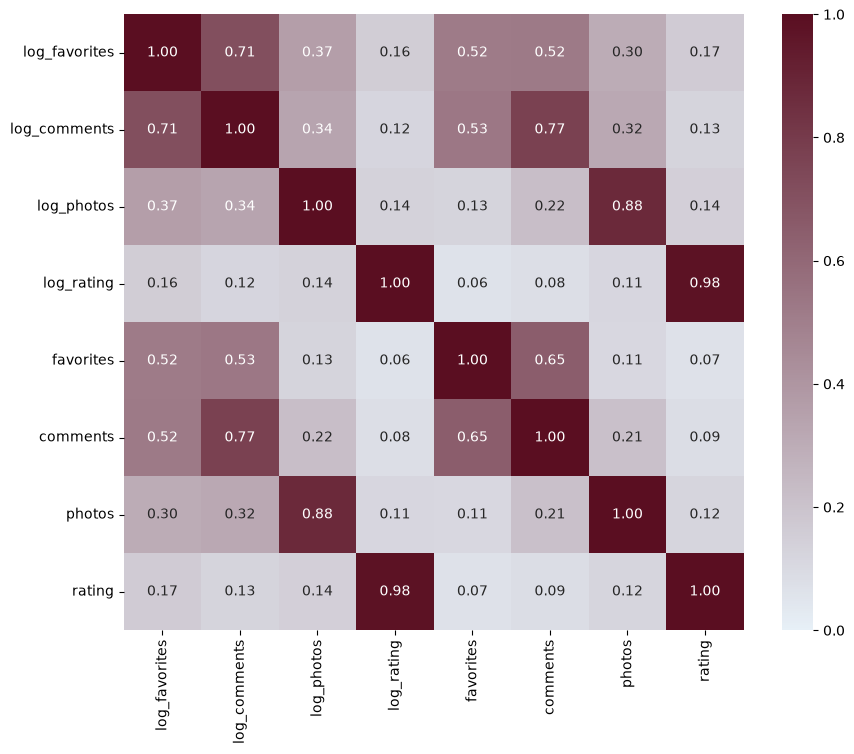

In [ ]:
# TODO - correlation matrix

SQL = """
    SELECT
        ln(1.0 + favorites_count) AS log_favorites,
        ln(1.0 + comments_count) AS log_comments,
        ln(1.0 + photos_count) AS log_photos,
        ln(1.0 + rating) AS log_rating,
        favorites_count AS favorites,
        comments_count AS comments,
        photos_count AS photos,
        rating
    FROM processed_projects
"""

df = con.execute(SQL).fetchdf()

corr_matrix = df.corr()

cmap = sns.blend_palette([
    "#e7f0f7",
    "#5a0e21"
], as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=cmap, vmin=0, vmax=1, ax=ax)

plt.show()

# Designers

In [10]:
con.execute(f"""
    DESCRIBE raw_designers
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,crochet_pattern_count,DOUBLE,YES,None,None,None
1,favorites_count,BIGINT,YES,None,None,None
2,id,BIGINT,YES,None,None,None
3,knitting_pattern_count,DOUBLE,YES,None,None,None
4,name,VARCHAR,YES,None,None,None
5,patterns_count,BIGINT,YES,None,None,None
6,permalink,VARCHAR,YES,None,None,None
7,notes,VARCHAR,YES,None,None,None
8,notes_html,VARCHAR,YES,None,None,None
9,users,"STRUCT(fave_curse VARCHAR, first_name VARCHAR,...",YES,None,None,None


# Yarns

In [11]:
con.execute(f"""
    DESCRIBE raw_yarns
""").fetchdf()

,column_name,column_type,null,key,default,extra
0,discontinued,BOOLEAN,YES,None,None,None
1,gauge_divisor,DOUBLE,YES,None,None,None
2,grams,DOUBLE,YES,None,None,None
3,id,BIGINT,YES,None,None,None
4,machine_washable,BOOLEAN,YES,None,None,None
5,max_gauge,DOUBLE,YES,None,None,None
6,min_gauge,DOUBLE,YES,None,None,None
7,name,VARCHAR,YES,None,None,None
8,permalink,VARCHAR,YES,None,None,None
9,rating_average,DOUBLE,YES,None,None,None


# Extracted Numbers

TODO - describe

These record types were extracted from the core pipelines processes:
- crafts
- languages
- needle_sizes
- pattern_attributes
- pattern_categories
- pattern_types
- users
- yarn_companies
- yarn_fibers
- yarn_weights

In [ ]:
extracted_views = [view for view in duckdb_views if view.startswith("extracted")]

for view in extracted_views:
    print(f"Describing {view}:")
    display(con.execute(f"""
        SELECT column_name, column_type
        FROM (DESCRIBE {view})
    """).fetchdf())


Describing extracted_crafts:


,column_name,column_type
0,id,BIGINT
1,name,VARCHAR
2,permalink,VARCHAR
3,extracted_at,TIMESTAMP WITH TIME ZONE


Describing extracted_languages:


,column_name,column_type
0,code,VARCHAR
1,id,BIGINT
2,name,VARCHAR
3,permalink,VARCHAR
4,short_name,VARCHAR
5,universal,BOOLEAN
6,extracted_at,TIMESTAMP WITH TIME ZONE


Describing extracted_needle_sizes:


,column_name,column_type
0,id,DOUBLE
1,us,DOUBLE
2,metric,DOUBLE
3,us_steel,VARCHAR
4,crochet,BOOLEAN
5,knitting,BOOLEAN
6,hook,VARCHAR
7,name,VARCHAR
8,pretty_metric,VARCHAR
9,extracted_at,TIMESTAMP WITH TIME ZONE


... (10 outputs left out)

Describing extracted_yarn_fibers:


,column_name,column_type
0,id,BIGINT
1,percentage,DOUBLE
2,fiber_type,"STRUCT(animal_fiber BOOLEAN, id DOUBLE, ""name""..."
3,fiber_category,"STRUCT(id DOUBLE, ""name"" VARCHAR, permalink VA..."
4,extracted_at,TIMESTAMP WITH TIME ZONE


Describing extracted_yarn_weights:


,column_name,column_type
0,crochet_gauge,VARCHAR
1,id,DOUBLE
2,knit_gauge,VARCHAR
3,max_gauge,"""NULL"""
4,min_gauge,"""NULL"""
5,name,VARCHAR
6,ply,VARCHAR
7,wpi,VARCHAR
8,extracted_at,TIMESTAMP WITH TIME ZONE


# HW1 Example: Joining Data & getting summary stats